# Import dependencies

In [66]:

import numpy as np
import copy
import matplotlib.pyplot as plt
import sklearn
import sklearn.datasets
import sklearn.linear_model

In [67]:
import seaborn as sns

# my plot style: greens on a white grid
sns.set_theme(style='whitegrid', palette='Greens_d')

 # Define dataset

In [68]:
def load_planar_dataset():
    np.random.seed(1)
    m = 400 # number of examples
    N = int(m/2) # number of points per class
    D = 2 # dimensionality
    X = np.zeros((m,D)) # data matrix where each row is a single example
    Y = np.zeros((m,1), dtype='uint8') # labels vector (0 for red, 1 for blue)
    a = 4 # maximum ray of the flower

    for j in range(2):
        ix = range(N*j,N*(j+1))
        t = np.linspace(j*3.12,(j+1)*3.12,N) + np.random.randn(N)*0.2 # theta
        r = a*np.sin(4*t) + np.random.randn(N)*0.2 # radius
        X[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
        Y[ix] = j
        
    X = X.T
    Y = Y.T

    return X, Y

# Load dataset

In [69]:
X, Y = load_planar_dataset()

# Visualize the data

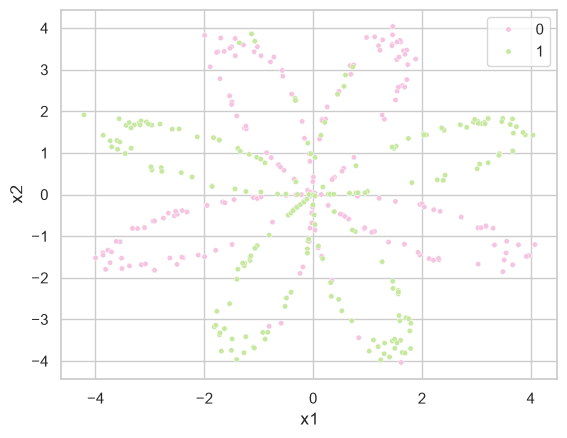

In [70]:
sns.scatterplot(x=X[0, :], y=X[1, :], hue=Y[0], palette='PiYG', s=15)  # pink vs green, two greens are hard to tell apart
plt.xlabel('x1')
plt.ylabel('x2');

In [71]:
print ('The shape of X is: ', X.shape)
print ('The shape of Y is: ', Y.shape)
print ('I have m = %d training examples!', (X.shape[1]))

The shape of X is:  (2, 400)
The shape of Y is:  (1, 400)
I have m = %d training examples! 400


# Define the hidden layer size

In [72]:
hidden_layer_nodes = 4

def layer_sizes(X, Y):
    n_x = X.shape[0]
    n_h = hidden_layer_nodes
    n_y = Y.shape[0]

    return (n_x, n_h, n_y)

# Define activation function

In [73]:
def sigmoid(x):
    
    s = 1/(1+np.exp(-x))
    return s

# Define function for parameter (weight and bias) initialization

In [74]:
def initialize_parameters(n_x, n_h, n_y):
    
    np.random.seed(2)

    W1 = np.random.randn(n_h,n_x) * 0.01
    b1 = np.zeros((n_h,1))
    
    W2 = np.random.randn(n_y,n_h) * 0.01
    b2 = np.zeros((n_y,1))

    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

# Forward propagation

In [75]:

def forward_propagation(X, parameters):
    
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]
    
    Z1 = np.dot(W1,X) + b1
    A1 = np.tanh(Z1)
    
    Z2 = np.dot(W2,A1) + b2
    A2 = sigmoid(Z2)
    
    cache = {"Z1": Z1,
             "A1": A1,
             "Z2": Z2,
             "A2": A2}
    
    return A2, cache

# Compute cost

In [76]:
def compute_cost(A2, Y):

    m = Y.shape[1] # number of examples

    logprobs = np.multiply(Y, np.log(A2)) + np.multiply((1 - Y), np.log(1 - A2))
    cost = - np.multiply(1/m, np.sum(logprobs))  
    cost = float(np.squeeze(cost))                             
    
    return cost

# Backward propagation

In [77]:
def backward_propagation(parameters, cache, X, Y):

    m = X.shape[1]
    W1 = parameters["W1"]
    W2 = parameters["W2"]
    
    A1 = cache["A1"]
    A2 = cache["A2"]

    dZ2 = A2 - Y
    dW2 = np.multiply(1/m, np.dot(dZ2, np.transpose(A1)))
    db2 = np.multiply(1/m, np.sum(dZ2, axis = 1, keepdims = True))
    dZ1 = np.multiply(np.dot(np.transpose(W2), dZ2), (1 - np.power(A1, 2)))
    dW1 = np.multiply(1/m, np.dot(dZ1, np.transpose(X)))
    db1 = np.multiply(1/m, np.sum(dZ1, axis = 1, keepdims = True))
    
    grads = {"dW1": dW1,
             "db1": db1,
             "dW2": dW2,
             "db2": db2}
    
    return grads

# Update parameters

In [78]:

def update_parameters(parameters, grads, learning_rate = 1.2):
    
    W1 = copy.deepcopy(parameters["W1"]) 
    b1 = copy.deepcopy(parameters["b1"]) 
    W2 = copy.deepcopy(parameters["W2"]) 
    b2 = copy.deepcopy(parameters["b2"]) 
    
    dW1 = copy.deepcopy(grads["dW1"]) 
    db1 = copy.deepcopy(grads["db1"])
    dW2 = copy.deepcopy(grads["dW2"])
    db2 = copy.deepcopy(grads["db2"])
    
    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1
    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2

    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

# Full NN model

In [79]:

def nn_model(X, Y, n_h, num_iterations = 10000, print_cost=False):
    
    np.random.seed(3)
    n_x = layer_sizes(X, Y)[0]
    n_y = layer_sizes(X, Y)[2]
    
    parameters = initialize_parameters(n_x, n_h, n_y)
   
    for i in range(0, num_iterations):
        
        A2, cache = forward_propagation(X, parameters)
        cost = compute_cost(A2, Y)
        grads = backward_propagation(parameters, cache, X, Y)
        parameters = update_parameters(parameters, grads, learning_rate = 1.2)
        
        # Print the cost every 1000 iterations
        if print_cost and i % 1000 == 0:
            print ("Cost after iteration %i: %f" %(i, cost))

    return parameters

# Test on our dataset

In [80]:
parameters = nn_model(X, Y, n_h = 4, num_iterations = 100000, print_cost=True)

Cost after iteration 0: 0.693048
Cost after iteration 1000: 0.288083
Cost after iteration 2000: 0.254385
Cost after iteration 3000: 0.233864
Cost after iteration 4000: 0.226792
Cost after iteration 5000: 0.222644
Cost after iteration 6000: 0.219731
Cost after iteration 7000: 0.217504
Cost after iteration 8000: 0.219447
Cost after iteration 9000: 0.218605
Cost after iteration 10000: 0.217904
Cost after iteration 11000: 0.217301
Cost after iteration 12000: 0.216780
Cost after iteration 13000: 0.216325
Cost after iteration 14000: 0.215921
Cost after iteration 15000: 0.215559
Cost after iteration 16000: 0.215231
Cost after iteration 17000: 0.214932
Cost after iteration 18000: 0.214658
Cost after iteration 19000: 0.214404
Cost after iteration 20000: 0.214169
Cost after iteration 21000: 0.213949
Cost after iteration 22000: 0.213744
Cost after iteration 23000: 0.213551
Cost after iteration 24000: 0.213369
Cost after iteration 25000: 0.213198
Cost after iteration 26000: 0.213035
Cost after ite

# Predict function

In [81]:
def predict(parameters, X):

    A2, cache = forward_propagation(X, parameters)
    predictions = (A2 > 0.5)

    return predictions

# Plot decision boundary

In [82]:
def plot_decision_boundary(model, X, y):
    # Set min and max values and give it some padding
    x_min, x_max = X[0, :].min() - 1, X[0, :].max() + 1
    y_min, y_max = X[1, :].min() - 1, X[1, :].max() + 1
    h = 0.01
    # Generate a grid of points with distance h between them
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    # Predict the function value for the whole grid
    Z = model(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    # Plot the contour and training examples
    plt.contourf(xx, yy, Z, cmap='PiYG', alpha=0.3)
    plt.ylabel('x2')
    plt.xlabel('x1')
    sns.scatterplot(x=X[0, :], y=X[1, :], hue=y.ravel(), palette='PiYG', s=15, edgecolor='black', linewidth=0.3, legend=False)

Text(0.5, 1.0, 'Decision Boundary for hidden layer size 4')

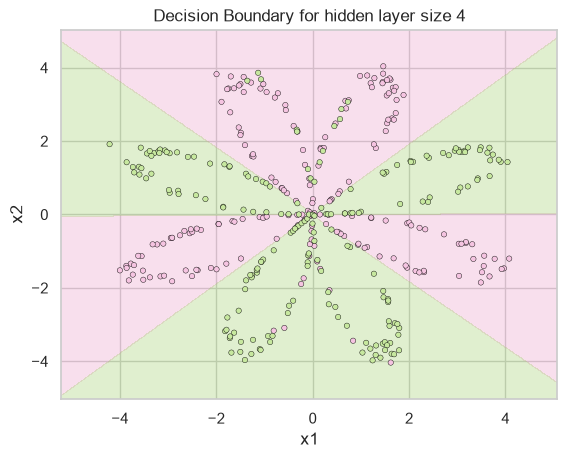

In [83]:
plot_decision_boundary(lambda x: predict(parameters, x.T), X, Y)
plt.title("Decision Boundary for hidden layer size " + str(4))

# Tuning hidden layer size

Accuracy for 1 hidden units: 67.5 %
Accuracy for 2 hidden units: 67.25 %
Accuracy for 3 hidden units: 90.75 %
Accuracy for 4 hidden units: 90.5 %
Accuracy for 5 hidden units: 91.25 %
Accuracy for 20 hidden units: 90.5 %
Accuracy for 50 hidden units: 90.75 %


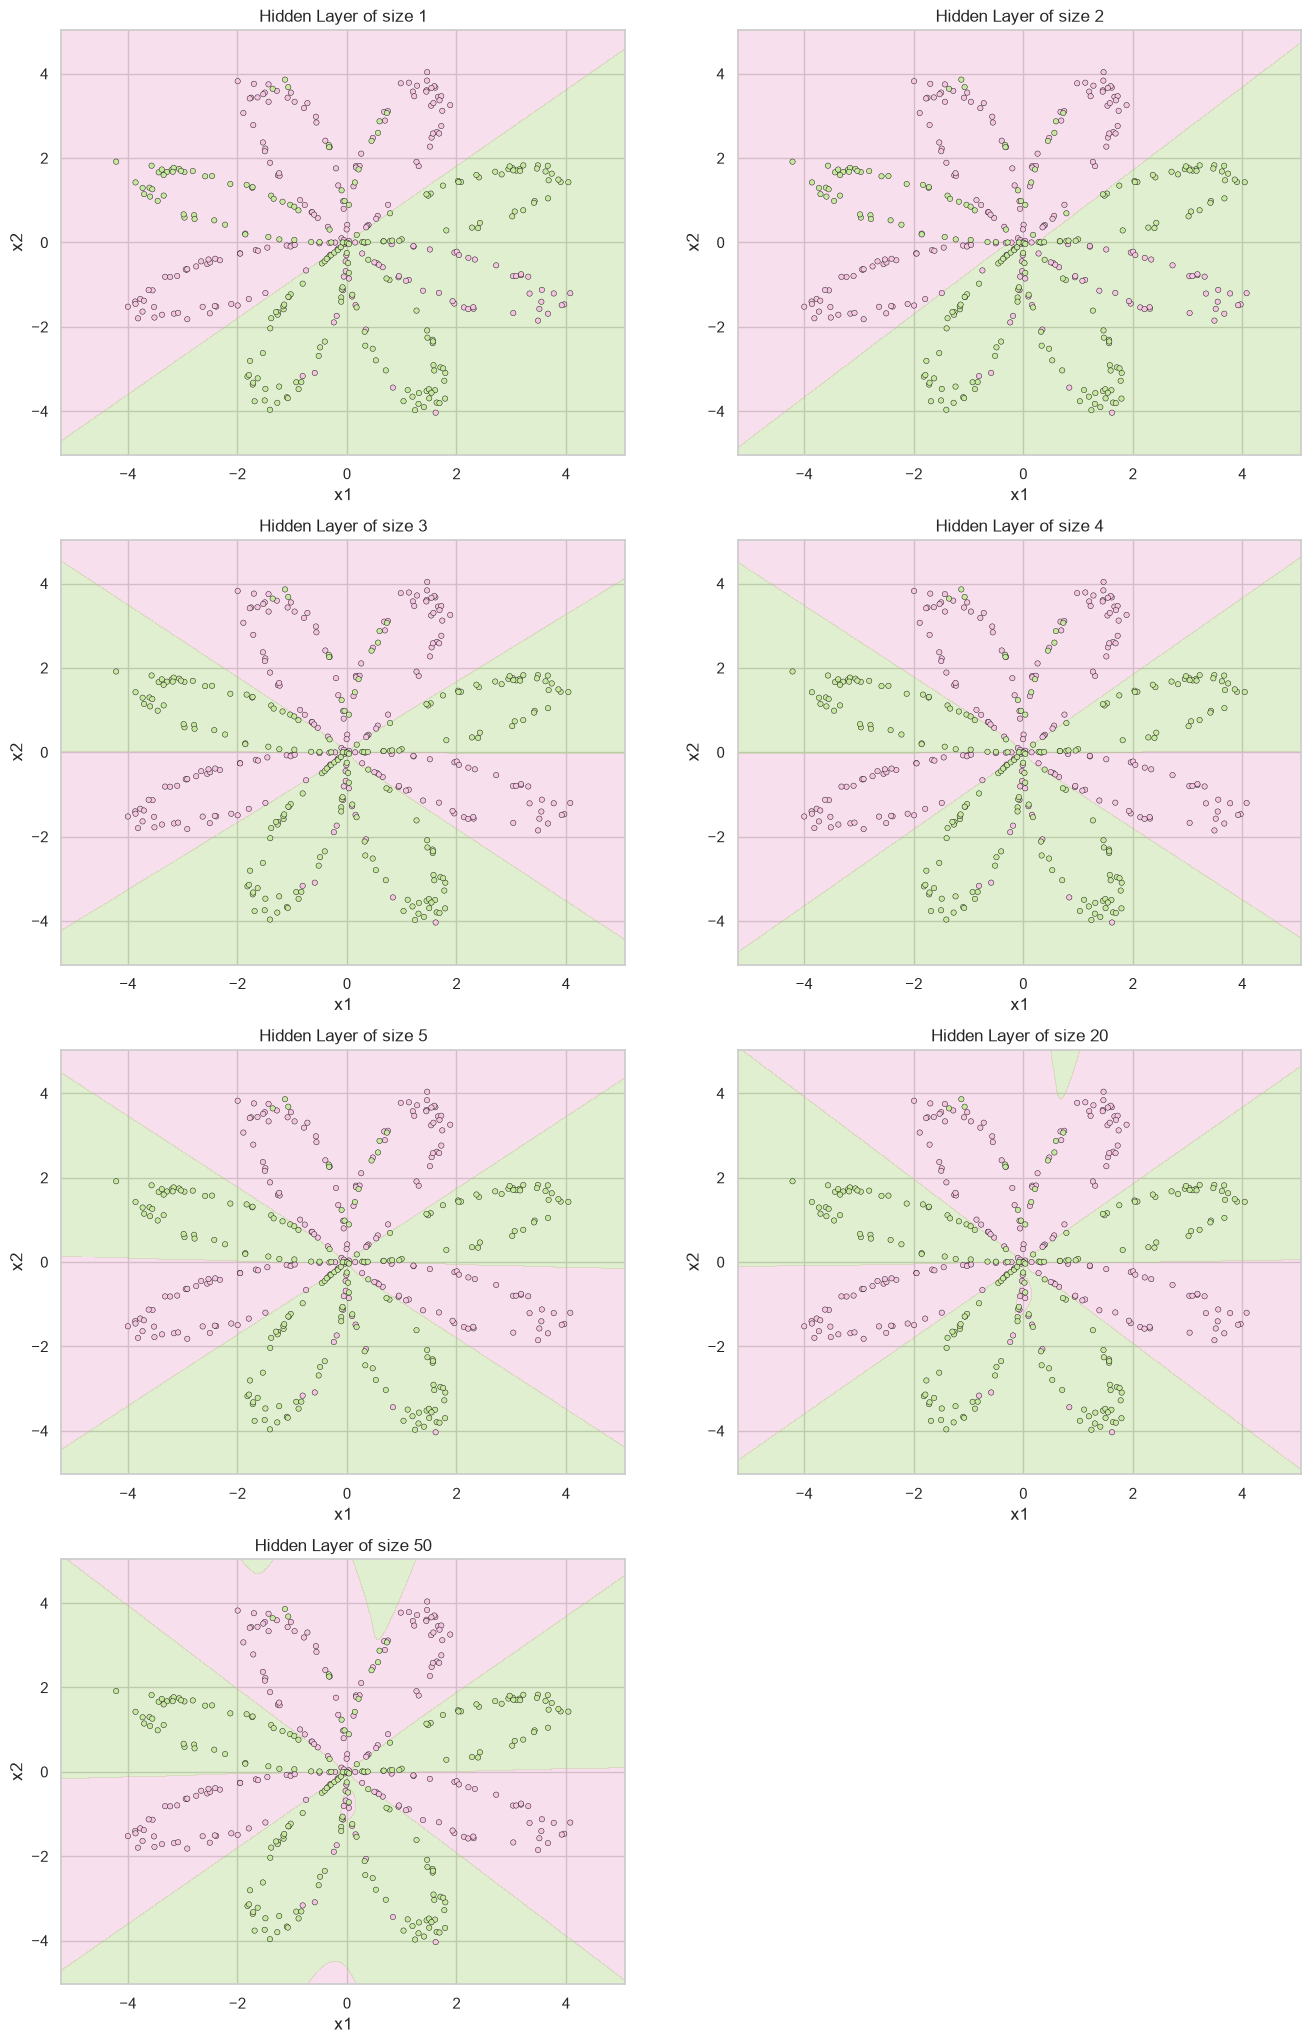

In [84]:
plt.figure(figsize=(16, 32))
hidden_layer_sizes = [1, 2, 3, 4, 5, 20, 50]
for i, n_h in enumerate(hidden_layer_sizes):
    plt.subplot(5, 2, i+1)
    plt.title('Hidden Layer of size %d' % n_h)
    parameters = nn_model(X, Y, n_h, num_iterations = 5000)
    plot_decision_boundary(lambda x: predict(parameters, x.T), X, Y)
    predictions = predict(parameters, X)
    accuracy = np.mean(predictions == Y) * 100  # float() on a 1x1 array failes in new numpy
    print ("Accuracy for {} hidden units: {} %".format(n_h, accuracy))

## Assignment: 

Run the notebook and test if everything runs fine. 

Test previous cell with different hidden layer size. 

Write your conclusion and observations.

## My experiment

I tried more sizes than in the cell above (including 8, 10 and 100). I also kept 100 points as a test set, because accuracy on the training data alone can't show overfitting.

In [85]:
# keep 100 points aside to check if biger layers overfit
np.random.seed(0)
order = np.random.permutation(X.shape[1])
X_tr, Y_tr = X[:, order[:300]], Y[:, order[:300]]
X_te, Y_te = X[:, order[300:]], Y[:, order[300:]]

sizes = [1, 2, 3, 4, 5, 8, 10, 20, 50, 100]
train_acc, test_acc = [], []
for n_h in sizes:
    params = nn_model(X_tr, Y_tr, n_h, num_iterations=5000)
    train_acc.append(np.mean(predict(params, X_tr) == Y_tr) * 100)
    test_acc.append(np.mean(predict(params, X_te) == Y_te) * 100)
    print(f"{n_h} hidden units: train {train_acc[-1]:.1f} %, test {test_acc[-1]:.1f} %")

1 hidden units: train 66.7 %, test 68.0 %
2 hidden units: train 65.3 %, test 64.0 %
3 hidden units: train 91.0 %, test 90.0 %
4 hidden units: train 90.7 %, test 89.0 %
5 hidden units: train 90.3 %, test 87.0 %
8 hidden units: train 92.0 %, test 87.0 %
10 hidden units: train 92.3 %, test 88.0 %
20 hidden units: train 91.7 %, test 87.0 %
50 hidden units: train 92.3 %, test 88.0 %
100 hidden units: train 92.3 %, test 88.0 %


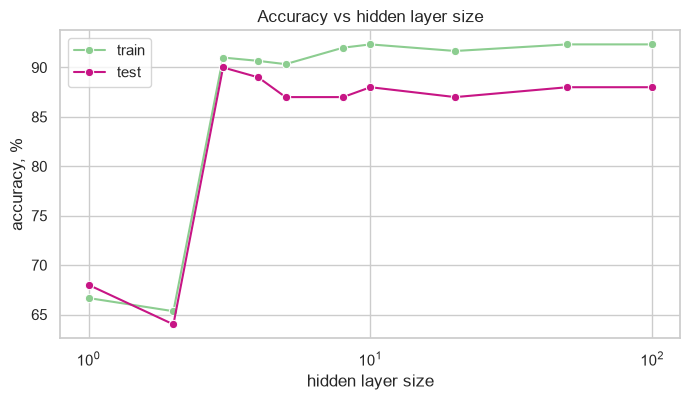

In [86]:
plt.figure(figsize=(8, 4))
sns.lineplot(x=sizes, y=train_acc, marker='o', label='train')
sns.lineplot(x=sizes, y=test_acc, marker='o', label='test', color='mediumvioletred')
plt.xscale('log')  # sizes go from 1 to 100
plt.xlabel('hidden layer size')
plt.ylabel('accuracy, %')
plt.title('Accuracy vs hidden layer size')
plt.show()

## Longer training

All runs above use 5000 iterations. Here I train the 50 unit network for 20000 iterations to see if it starts to overfit when it has more time.

50 units, 5000 iterations: train 92.3 %, test 88.0 %
50 units, 20000 iterations: train 95.7 %, test 88.0 %


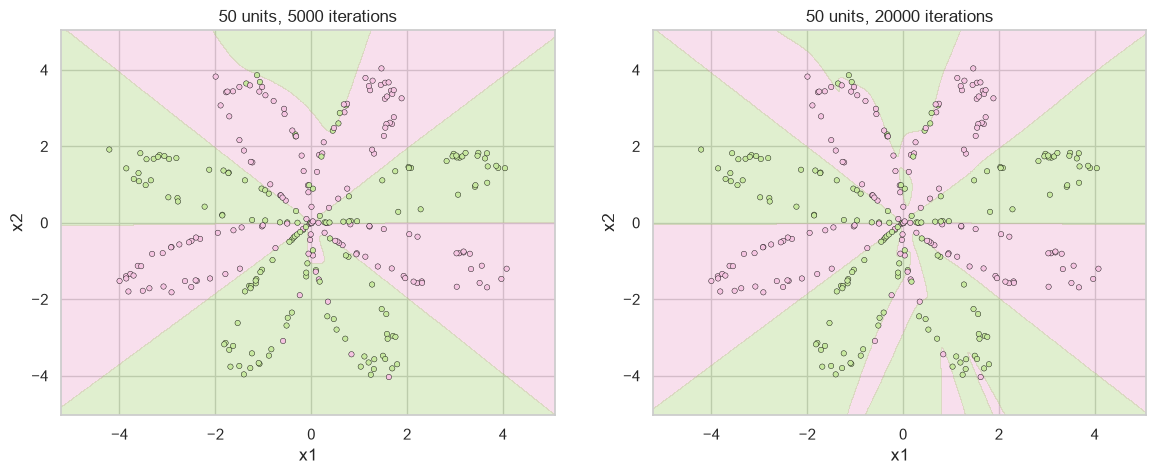

In [87]:
plt.figure(figsize=(14, 5))
for i, iters in enumerate([5000, 20000]):
    params = nn_model(X_tr, Y_tr, 50, num_iterations=iters)
    tr = np.mean(predict(params, X_tr) == Y_tr) * 100
    te = np.mean(predict(params, X_te) == Y_te) * 100
    print(f"50 units, {iters} iterations: train {tr:.1f} %, test {te:.1f} %")

    plt.subplot(1, 2, i + 1)
    plot_decision_boundary(lambda x: predict(params, x.T), X_tr, Y_tr)
    plt.title(f'50 units, {iters} iterations')
plt.show()

## My conclusions

The network needs at least 3 hidden units. With 1 or 2 units the boundary is one straight line, so it only gets about 65 % right. With 3 units it jumps to around 90 % on train and test, because it can cut the plane into wedges that roughly follow the petals.

More units don't really help. From 8 units up train goes to about 92 % while test stays at 87-88 %, but with only 100 test points (one point is 1 %) I wouldn't trust such small differences. I would pick 3 to 5 units. Most mistakes are where a petal bends across the edge of a wedge, and near the centre where the petals meet.

Training the 50 unit network for 20000 iterations instead of 5000 raised train accuracy from 92.3 % to 95.7 %, but test stayed at 88 %. The boundary gets thin strips that reach for single points, so this is real overfitting and another reason to keep the layer small.